# Giá trị của thông tin lịch trong dự báo nhu cầu bán lẻ theo ngày: ablation có kiểm định trên LightGBM và LSTM (M5)
*Value of calendar information in daily retail demand forecasting: a controlled ablation with LightGBM and LSTM.*

**Phiên bản 3.** Mục 0–15 giữ nguyên như phiên bản 2 (kèm kết quả đã chạy). Mục 16 ở cuối notebook là các thí nghiệm bổ sung; chạy toàn bộ notebook từ đầu trong cùng một phiên Colab.

**Dataset:** M5 Forecasting – Accuracy (Walmart) · **Scope:** one store (CA_1) × one category (FOODS), stratified sample of items
**Main task:** 1-day-ahead demand forecasting for each item, using demand history + calendar/date-type + price information.

### Experimental protocol (read this first)
| Element | Choice |
|---|---|
| Horizon | **1 day ahead** for the main experiment (multi-step 7-day is an optional extension, last section) |
| Split | Chronological 70 / 15 / 15 (train / validation / test), no shuffling |
| Models | Naive, Seasonal Naive (lag 7), MA28 · LightGBM · LSTM (two-branch, uses *future-known* calendar of the forecast day) |
| Ablation | **A** = demand history only · **B** = A + calendar & date type · **C** = B + price & SNAP |
| Fairness | Same table, same split, same evaluation rows `(item_id, date)` for every model; same item information (LightGBM `item_cat`, LSTM item embedding) |
| Metrics | MAE, RMSE, **WAPE**, **RMSSE**, **Bias** (+ sMAPE as auxiliary only) · Diebold–Mariano test · error by date type |


## 0. Setup and configuration (Problem and Task Definition)
Formal task: for item *i* and day *t*, predict  ŷ(i,t) = f( demand(i, t-28 … t-1),  x(i,t) ), where x(i,t) are variables **known in advance** for day t (calendar, date type, SNAP, price).

In [ ]:
import os, gc, random, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from numpy.lib.stride_tricks import sliding_window_view

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 50)

# --- TẢI DỮ LIỆU TRỰC TIẾP TỪ KAGGLE MỚI ---
try:
    import kagglehub
    print("Đang tải dữ liệu M5 từ Kaggle (aryayadav0513)...")
    # Tải dataset m5-forecasting-accuracy từ link mới bạn cung cấp
    KAGGLE_PATH = kagglehub.dataset_download("aryayadav0513/m5-forecasting-accuracy")
    DATA_DIR = KAGGLE_PATH
    print(f"Dữ liệu đã được tải về thành công tại: {DATA_DIR}")
except Exception as e:
    print(f"Lỗi khi tải từ Kaggle: {e}. Chuyển sang sử dụng thư mục tạm cục bộ.")
    DATA_DIR = "/content/M5_Data"

OUT_DIR   = os.path.join(DATA_DIR, "outputs")
os.makedirs(OUT_DIR, exist_ok=True)

STORE_ID  = "CA_1"
CAT_ID    = "FOODS"
N_ITEMS   = 100            # items sampled (stratified by sales volume); 100-200 runs fine on Colab
N_BINS    = 5              # number of volume strata
SEED      = 42

LOOKBACK  = 28             # LSTM input window (days)
HORIZON   = 1              # main experiment = 1-day-ahead (do NOT change; use the extension section for H>1)
TRAIN_FRAC, VAL_FRAC = 0.70, 0.15

# LSTM training
SEEDS       = [42, 7, 2024]
# several seeds -> report mean ± std (DL is stochastic)
EPOCHS      = 40
BATCH_SIZE  = 256
PATIENCE    = 6
LSTM_UNITS  = (64, 32)
DROPOUT     = 0.2
LSTM_LOSS   = "poisson"        # "poisson" (count data, pairs with softplus output) | "mse" | "huber"

# Optional extension: 7-day-ahead (direct strategy for both models)
RUN_MULTISTEP = False
MS_H          = 7
MS_SEEDS      = [42]
# ------------------------------------------------------------------------------

random.seed(SEED); np.random.seed(SEED)
STATE = STORE_ID.split("_")[0]
assert HORIZON == 1, "Main experiment is 1-day-ahead. Use RUN_MULTISTEP for longer horizons."

def save_fig(name):
    plt.tight_layout()
    plt.savefig(os.path.join(OUT_DIR, name), dpi=150, bbox_inches="tight")
    plt.show()

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


## 1. Load data and build calendar / date-type features (source, features, feature engineering)
**Date-type definition** (priority order): `Holiday` (National/Religious event) > `Other_Event` (Cultural/Sporting…) > `Pre_Event` (1–2 days before any event) > `Weekend` > `Weekday`.
Fix vs. the old notebook: `is_event` and `is_holiday` used to be identical (both = "event column not null"). Now `is_holiday` uses `event_type`.

In [ ]:
DATE_TYPES      = ["Weekday", "Weekend", "Pre_Event", "Other_Event", "Holiday"]
HOLIDAY_TYPES   = ["National", "Religious"]

def build_calendar_features(calendar):
    c = calendar.copy()
    c["date"] = pd.to_datetime(c["date"]).astype("datetime64[ns]")
    c = c.sort_values("date").reset_index(drop=True)

    c["day_of_week"]  = c["date"].dt.dayofweek
    c["day_of_month"] = c["date"].dt.day
    c["week_of_year"] = c["date"].dt.isocalendar().week.astype(int)
    c["month"]        = c["date"].dt.month
    c["is_weekend"]   = (c["day_of_week"] >= 5).astype(int)

    c["has_event"]  = (c["event_name_1"].notna() | c["event_name_2"].notna()).astype(int)
    c["is_holiday"] = (c["event_type_1"].isin(HOLIDAY_TYPES) | c["event_type_2"].isin(HOLIDAY_TYPES)).astype(int)

    ev_date = c["date"].where(c["has_event"] == 1)                       # date of each event day, NaT elsewhere
    c["days_to_next_event"]    = (ev_date.bfill() - c["date"]).dt.days.clip(upper=14).fillna(14)
    c["days_since_last_event"] = (c["date"] - ev_date.ffill()).dt.days.clip(upper=14).fillna(14)
    c["is_pre_event"] = c["days_to_next_event"].between(1, 2).astype(int)

    c["date_type"] = np.select(
        [c["is_holiday"] == 1, c["has_event"] == 1, c["is_pre_event"] == 1, c["is_weekend"] == 1],
        ["Holiday", "Other_Event", "Pre_Event", "Weekend"], default="Weekday")
    for dt in DATE_TYPES:
        c[f"dt_{dt}"] = (c["date_type"] == dt).astype(int)

    # cyclical encodings + scaled distances (used by the LSTM)
    c["dow_sin"]   = np.sin(2 * np.pi * c["day_of_week"] / 7)
    c["dow_cos"]   = np.cos(2 * np.pi * c["day_of_week"] / 7)
    c["month_sin"] = np.sin(2 * np.pi * (c["month"] - 1) / 12)
    c["month_cos"] = np.cos(2 * np.pi * (c["month"] - 1) / 12)
    c["dts"] = c["days_to_next_event"] / 14.0
    c["dsl"] = c["days_since_last_event"] / 14.0

    c["snap"] = c[f"snap_{STATE}"].astype(int)                           # SNAP day of the store's state
    return c

calendar_raw = pd.read_csv(f"{DATA_DIR}/calendar.csv")
cal = build_calendar_features(calendar_raw)
CAL_KEEP = ["d", "date", "wm_yr_wk", "day_of_week", "day_of_month", "week_of_year", "month",
            "is_weekend", "has_event", "is_holiday", "is_pre_event", "days_to_next_event",
            "days_since_last_event", "date_type", "snap", "dow_sin", "dow_cos", "month_sin",
            "month_cos", "dts", "dsl"] + [f"dt_{d}" for d in DATE_TYPES]
print("Calendar:", cal.shape, "|", cal["date"].min().date(), "->", cal["date"].max().date())
print(cal["date_type"].value_counts())

Calendar: (1969, 36) | 2011-01-29 -> 2016-06-19
date_type
Weekday        1117
Weekend         395
Pre_Event       295
Holiday         108
Other_Event      54
Name: count, dtype: int64


## 2. Load sales for the chosen store/category and sample items (stratified)
Fix vs. old notebook: items are **not** the first 20 alphabetical ones (all from one department). We split the item pool into volume quintiles and sample the same number from each, with a fixed seed.

In [ ]:
sales_path = f"{DATA_DIR}/sales_train_evaluation.csv"
parts = []
for chunk in pd.read_csv(sales_path, chunksize=2000):                   # chunked read -> low RAM
    chunk = chunk[(chunk["store_id"] == STORE_ID) & (chunk["cat_id"] == CAT_ID)]
    if len(chunk):
        parts.append(chunk)
sales_wide = pd.concat(parts, ignore_index=True)
del parts; gc.collect()

day_cols = [c for c in sales_wide.columns if c.startswith("d_")]
sales_wide["total_volume"] = sales_wide[day_cols].sum(axis=1)
pool_all = len(sales_wide)
sales_wide = sales_wide[sales_wide["total_volume"] > 0].reset_index(drop=True)   # drop items that never sell
sales_wide["vol_bin"] = pd.qcut(sales_wide["total_volume"].rank(method="first"), N_BINS, labels=False)

per_bin = N_ITEMS // N_BINS
selected = pd.concat([
    sales_wide[sales_wide["vol_bin"] == b].sample(min(per_bin, (sales_wide["vol_bin"] == b).sum()), random_state=SEED)
    for b in range(N_BINS)
], ignore_index=True)

print(f"{STORE_ID}/{CAT_ID}: {pool_all} items in pool, {len(sales_wide)} with sales -> {len(selected)} selected")
print(selected.groupby("vol_bin")["total_volume"].agg(["count", "min", "median", "max"]))
print("Departments:", selected["dept_id"].value_counts().to_dict())
del sales_wide; gc.collect()

CA_1/FOODS: 1437 items in pool, 1437 with sales -> 100 selected
         count   min  median    max
vol_bin                            
0           20   106   572.5    651
1           20   783  1076.0   1364
2           20  1429  1968.0   2281
3           20  2377  2920.0   4012
4           20  4449  9405.0  88846
Departments: {'FOODS_3': 61, 'FOODS_2': 23, 'FOODS_1': 16}


0

## 3. Wide → long, merge calendar and prices
Fix vs. old notebook: rows where `sell_price` is NaN are **dropped** (the item was not yet on sale, so demand = 0 there is not real demand). The old notebook imputed the median price and trained on those fake zeros, and LightGBM/LSTM saw different data.

In [ ]:
id_cols = ["id", "item_id", "dept_id", "cat_id", "store_id", "state_id"]
sales_long = selected.melt(id_vars=id_cols + ["vol_bin", "total_volume"],
                           value_vars=day_cols, var_name="d", value_name="demand")
sales_long["demand"] = sales_long["demand"].astype("float32")
sales_long = sales_long.merge(cal[CAL_KEEP], on="d", how="left")

item_set = set(selected["item_id"])
price_parts = []
for chunk in pd.read_csv(f"{DATA_DIR}/sell_prices.csv", chunksize=200_000):
    chunk = chunk[(chunk["store_id"] == STORE_ID) & (chunk["item_id"].isin(item_set))]
    if len(chunk):
        price_parts.append(chunk)
prices = pd.concat(price_parts, ignore_index=True)
del price_parts; gc.collect()

sales_long = sales_long.merge(prices[["store_id", "item_id", "wm_yr_wk", "sell_price"]],
                              on=["store_id", "item_id", "wm_yr_wk"], how="left")
n_before = len(sales_long)
sales_long = sales_long[sales_long["sell_price"].notna()].copy()
print(f"Rows before price filter: {n_before:,} | dropped (item not yet on sale): {n_before - len(sales_long):,} | kept: {len(sales_long):,}")

sales_long = sales_long.sort_values(["item_id", "date"]).reset_index(drop=True)
ITEM_LIST = sorted(sales_long["item_id"].unique())
item_to_code = {k: i for i, k in enumerate(ITEM_LIST)}
sales_long["item_code"] = sales_long["item_id"].map(item_to_code).astype("int32")

# each item's series must be contiguous daily (LSTM windows rely on it)
gaps = sales_long.groupby("item_id")["date"].apply(lambda s: int((s.diff().dropna().dt.days != 1).sum()))
assert gaps.sum() == 0, "Found gaps in daily series"
del selected, prices; gc.collect()

Rows before price filter: 194,100 | dropped (item not yet on sale): 35,014 | kept: 159,086


756

## 4. Feature engineering: lags, rolling statistics, price features
All history features use only **past** values (`shift`), so there is no look-ahead leakage.

In [ ]:
g = sales_long.groupby("item_id", sort=False)

# --- historical demand ---
for k in [1, 7, 14, 28]:
    sales_long[f"lag_{k}"] = g["demand"].shift(k)
sales_long["_s1"] = g["demand"].shift(1)
gs = sales_long.groupby("item_id", sort=False)["_s1"]
sales_long["rolling_mean_7"]  = gs.transform(lambda x: x.rolling(7).mean())
sales_long["rolling_mean_28"] = gs.transform(lambda x: x.rolling(28).mean())
sales_long["rolling_std_28"]  = gs.transform(lambda x: x.rolling(28).std())
sales_long.drop(columns="_s1", inplace=True)
sales_long["log_demand"] = np.log1p(sales_long["demand"])

# --- price features (price is known in advance, so it is a legitimate future covariate) ---
gp = sales_long.groupby("item_id", sort=False)["sell_price"]
sales_long["price_rel_28"]   = (sales_long["sell_price"] / gp.transform(lambda x: x.rolling(28, min_periods=1).mean())).clip(0.5, 1.5)
sales_long["price_change_7"] = (sales_long["sell_price"] / gp.shift(7) - 1).fillna(0).clip(-0.5, 0.5)

# --- fixed categorical dtypes (same categories in train/val/test) ---
sales_long["item_cat"]      = pd.Categorical(sales_long["item_id"],   categories=ITEM_LIST)
sales_long["date_type_cat"] = pd.Categorical(sales_long["date_type"], categories=DATE_TYPES)

print("Missing values in key columns (expected: only lag/rolling at the start of each series):")
print(sales_long[["demand", "sell_price", "lag_1", "lag_28", "rolling_mean_28", "price_rel_28"]].isna().sum())

Missing values in key columns (expected: only lag/rolling at the start of each series):
demand                0
sell_price            0
lag_1               100
lag_28             2800
rolling_mean_28    2800
price_rel_28          0
dtype: int64


## 5. Chronological split 70 / 15 / 15 and rows used for tabular models
`model_df` = rows with a full 28-day history. The LSTM will be evaluated on exactly the same `(item_id, date)` rows.

In [ ]:
_tmp = sales_long.dropna(subset=["lag_28", "rolling_mean_28"])
dates = np.sort(_tmp["date"].unique()); n_dates = len(dates)
train_end = pd.Timestamp(dates[int(n_dates * TRAIN_FRAC) - 1])
val_end   = pd.Timestamp(dates[int(n_dates * (TRAIN_FRAC + VAL_FRAC)) - 1])
del _tmp

sales_long["split"] = np.where(sales_long["date"] <= train_end, "train",
                        np.where(sales_long["date"] <= val_end, "val", "test"))
model_df = sales_long.dropna(subset=["lag_28", "rolling_mean_28"]).copy()

train = model_df[model_df["split"] == "train"].copy()
val   = model_df[model_df["split"] == "val"].copy()
test  = model_df[model_df["split"] == "test"].copy()

split_table = pd.DataFrame({
    s: {"from": d["date"].min().date(), "to": d["date"].max().date(), "days": d["date"].nunique(), "rows": len(d)}
    for s, d in [("train", train), ("val", val), ("test", test)]}).T
print(split_table)

             from          to  days   rows
train  2011-02-26  2014-10-26  1339  99319
val    2014-10-27  2015-08-09   287  28267
test   2015-08-10  2016-05-22   287  28700


## 6. Exploratory analysis and dataset statistics (Report §6 – fill the dataset table from this output)

=== Dataset summary (for Report §6) ===
Items: 100 | Rows (model_df): 156,286 | Period: 2011-02-26 -> 2016-05-22
Target 'demand' (units/day):
count    156286.000
mean          2.546
std           6.402
min           0.000
25%           0.000
50%           1.000
75%           3.000
max         133.000
Share of zero-demand days: 46.3%

Days per date type (calendar, all days):
date_type
Weekday        1117
Weekend         395
Pre_Event       295
Holiday         108
Other_Event      54

Mean demand by date type:
date_type
Holiday        2.367
Other_Event    2.539
Pre_Event      2.754
Weekday        2.251
Weekend        3.257

Mean demand on SNAP vs non-SNAP days:
snap
0    2.438
1    2.766


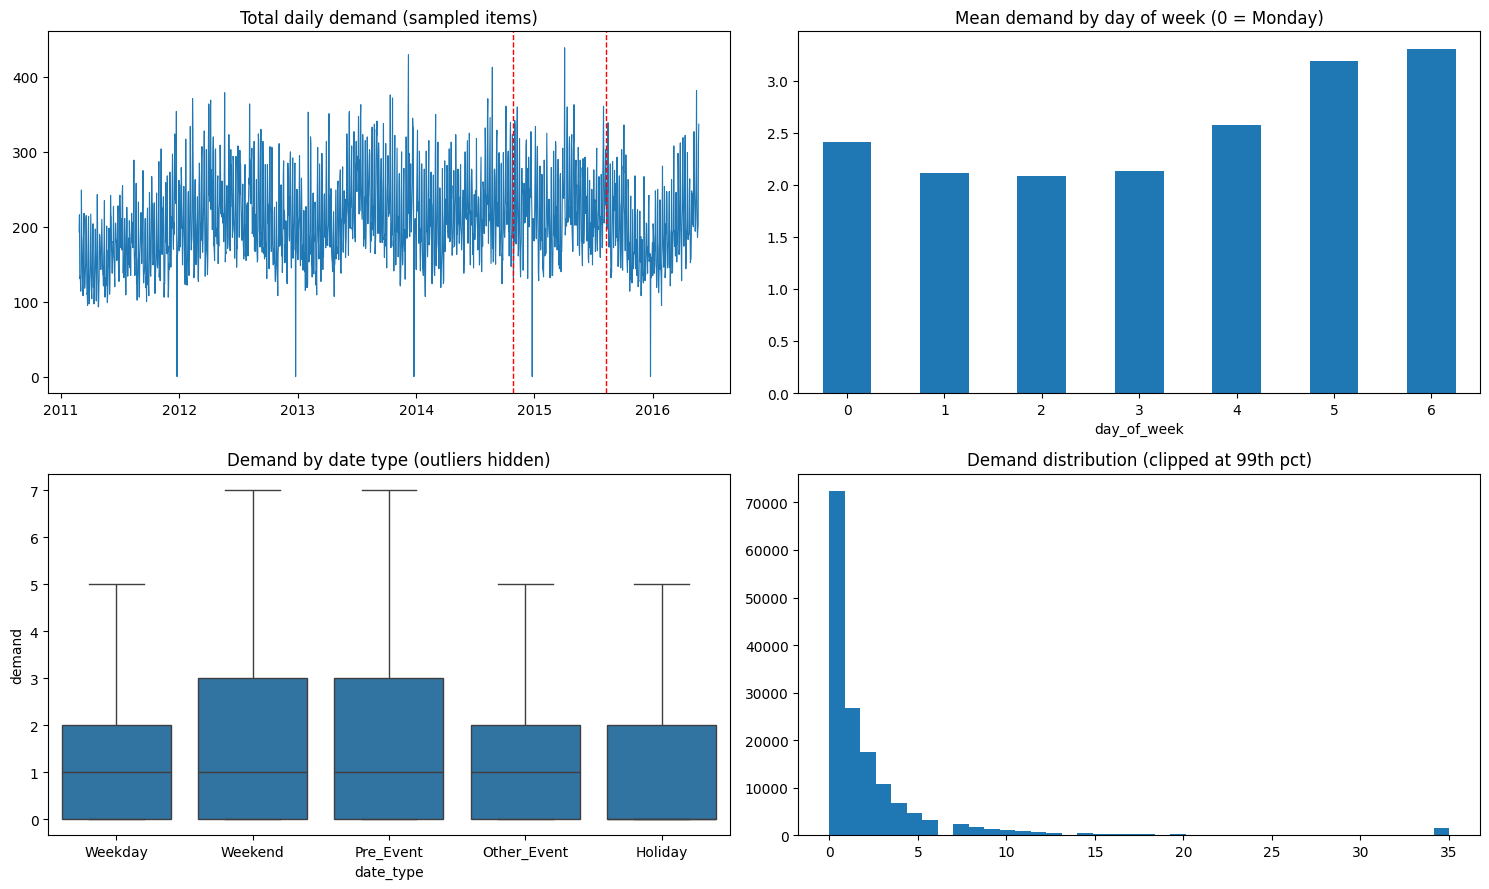

In [ ]:
print("=== Dataset summary (for Report §6) ===")
print("Items:", model_df["item_id"].nunique(), "| Rows (model_df):", f"{len(model_df):,}",
      "| Period:", model_df["date"].min().date(), "->", model_df["date"].max().date())
print("Target 'demand' (units/day):"); print(model_df["demand"].describe().round(3).to_string())
print(f"Share of zero-demand days: {100 * (model_df['demand'] == 0).mean():.1f}%")
print("\nDays per date type (calendar, all days):"); print(cal["date_type"].value_counts().to_string())
print("\nMean demand by date type:"); print(model_df.groupby("date_type")["demand"].mean().round(3).to_string())
print("\nMean demand on SNAP vs non-SNAP days:"); print(model_df.groupby("snap")["demand"].mean().round(3).to_string())

fig, ax = plt.subplots(2, 2, figsize=(15, 9))
daily = model_df.groupby("date")["demand"].sum()
ax[0, 0].plot(daily.index, daily.values, lw=0.8); ax[0, 0].set_title("Total daily demand (sampled items)")
for d in [train_end, val_end]: ax[0, 0].axvline(d, color="red", ls="--", lw=1)
model_df.groupby("day_of_week")["demand"].mean().plot(kind="bar", ax=ax[0, 1], rot=0)
ax[0, 1].set_title("Mean demand by day of week (0 = Monday)")
sns.boxplot(data=model_df, x="date_type", y="demand", order=DATE_TYPES, ax=ax[1, 0], showfliers=False)
ax[1, 0].set_title("Demand by date type (outliers hidden)")
ax[1, 1].hist(model_df["demand"].clip(upper=model_df["demand"].quantile(0.99)), bins=40)
ax[1, 1].set_title("Demand distribution (clipped at 99th pct)")
save_fig("fig_eda.png")

## 7. Feature sets for the ablation (Report: Methods)
| Set | LightGBM features | LSTM inputs |
|---|---|---|
| **A** – history only | lags, rolling stats, item | 28-day window of log-demand + item embedding |
| **B** – A + calendar/date type | + weekday, month, weekend, holiday, event, pre-event, distance to events, `date_type` | + same calendar variables for the past window **and for the forecast day** (future branch) |
| **C** – B + price/SNAP | + SNAP, price, relative price, price change | + SNAP, relative price, price change (window + forecast day) |

Comparing A→B isolates the contribution of calendar/date-type information; B→C isolates price/SNAP.

In [ ]:
HIST_LGB  = ["lag_1", "lag_7", "lag_14", "lag_28", "rolling_mean_7", "rolling_mean_28", "rolling_std_28"]
CAL_LGB   = ["day_of_week", "day_of_month", "week_of_year", "month", "is_weekend", "is_holiday", "has_event",
             "is_pre_event", "days_to_next_event", "days_since_last_event", "date_type_cat"]
PRICE_LGB = ["snap", "sell_price", "price_rel_28", "price_change_7"]
LGB_SETS = {
    "A": HIST_LGB + ["item_cat"],
    "B": HIST_LGB + CAL_LGB + ["item_cat"],
    "C": HIST_LGB + CAL_LGB + PRICE_LGB + ["item_cat"],
}

CAL_LSTM   = ["dow_sin", "dow_cos", "month_sin", "month_cos", "is_weekend", "is_holiday", "has_event",
              "is_pre_event", "dts", "dsl"] + [f"dt_{d}" for d in DATE_TYPES]
PRICE_LSTM = ["snap", "price_rel_28", "price_change_7"]
LSTM_SETS = {
    "A": dict(hist=["log_demand"],                              fut=[]),
    "B": dict(hist=["log_demand"] + CAL_LSTM,                   fut=CAL_LSTM),
    "C": dict(hist=["log_demand"] + CAL_LSTM + PRICE_LSTM,      fut=CAL_LSTM + PRICE_LSTM),
}
for k in LGB_SETS: print(f"LightGBM-{k}: {len(LGB_SETS[k])} features")
for k in LSTM_SETS: print(f"LSTM-{k}: hist={len(LSTM_SETS[k]['hist'])} channels, future={len(LSTM_SETS[k]['fut'])} channels")

LightGBM-A: 8 features
LightGBM-B: 19 features
LightGBM-C: 23 features
LSTM-A: hist=1 channels, future=0 channels
LSTM-B: hist=16 channels, future=15 channels
LSTM-C: hist=19 channels, future=18 channels


## 8. Evaluation framework (Report: Evaluation metrics)
* **MAE, RMSE** – scale-dependent. **WAPE** = Σ|e| / Σy – easy to interpret, robust to zeros. **RMSSE** – scaled by the naive one-step error on the training set of each item (M5 style). **Bias** = mean(ŷ − y): >0 over-forecast (excess stock), <0 under-forecast (stock-outs).
* sMAPE is kept **only as an auxiliary metric**: with many zero-demand days it explodes (y = 0, ŷ > 0 → 200%).
* Diebold–Mariano test on daily aggregated loss differences (Newey–West variance) to check whether differences between models are statistically significant.
* All forecasts are clipped at 0 and evaluated on the **same rows** of `test_eval`.

In [ ]:
def wape(y, p):  return float(np.abs(y - p).sum() / (np.abs(y).sum() + 1e-8))
def bias(y, p):  return float(np.mean(p - y))

def metrics_row(df, col):
    y, p = df["demand"].to_numpy(float), df[col].to_numpy(float)
    return {"MAE": np.mean(np.abs(y - p)),
            "RMSE": np.sqrt(np.mean((y - p) ** 2)),
            "WAPE_%": 100 * wape(y, p),
            "RMSSE": np.sqrt(np.mean((y - p) ** 2 / df["scale"].to_numpy(float))),
            "Bias": bias(y, p),
            "sMAPE_%(aux)": 100 * np.mean(2 * np.abs(y - p) / (np.abs(y) + np.abs(p) + 1e-8))}

def metrics_table(df, cols):
    return pd.DataFrame({c: metrics_row(df, c) for c in cols}).T.round(4)

def dm_test(df, col1, col2, loss="abs", lag=7):
    """Diebold-Mariano on daily-aggregated loss. stat > 0 => col1 has HIGHER loss (worse) than col2."""
    e1, e2 = df["demand"] - df[col1], df["demand"] - df[col2]
    l1, l2 = (e1.abs(), e2.abs()) if loss == "abs" else (e1 ** 2, e2 ** 2)
    d = (l1 - l2).groupby(df["date"]).sum().to_numpy()
    n, dm = len(d), d.mean()
    var = np.var(d)
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * np.mean((d[k:] - dm) * (d[:-k] - dm))
    stat = dm / np.sqrt(var / n)
    return float(stat), float(2 * (1 - stats.norm.cdf(abs(stat))))

# evaluation frame: one row per (item_id, date) of the test period
test_eval = test[["item_id", "date", "demand", "date_type", "snap", "vol_bin"]].copy().reset_index(drop=True)
train_scale = train.groupby("item_id")["demand"].apply(lambda s: float(np.mean(np.diff(s.to_numpy()) ** 2)))
fallback = train_scale[train_scale > 0].median()
test_eval["scale"] = test_eval["item_id"].map(train_scale).replace(0, fallback).fillna(fallback)

# val frame (only used to select LightGBM hyper-parameters)
val_eval = val[["item_id", "date", "demand"]].copy().reset_index(drop=True)
print("Test rows:", len(test_eval), "| Test days:", test_eval["date"].nunique())

Test rows: 28700 | Test days: 287


## 9. Baselines
Naive (yesterday), Seasonal Naive (same weekday last week), Moving Average of the last 28 days.

In [ ]:
test_eval["Naive"]          = test["lag_1"].to_numpy()
test_eval["Seasonal Naive"] = test["lag_7"].to_numpy()
test_eval["MA28"]           = test["rolling_mean_28"].to_numpy()
print(metrics_table(test_eval, ["Naive", "Seasonal Naive", "MA28"]))

                   MAE    RMSE   WAPE_%   RMSSE    Bias  sMAPE_%(aux)
Naive           1.4456  2.9468  74.1171  1.0256 -0.0012       78.2650
Seasonal Naive  1.4838  2.8878  76.0750  1.0324  0.0038       82.8045
MA28            1.2658  2.4793  64.8984  0.7859 -0.0012      105.6971


## 10. LightGBM (machine-learning baseline)
* Objective **Tweedie** (non-negative, zero-inflated count data – common in M5 solutions) instead of plain L2.
* `subsample_freq=1` added (in the old notebook `subsample=0.8` had no effect without it).
* `year` removed from features (a tree cannot extrapolate to unseen years).
* Small grid over tree complexity, selected by **validation WAPE**; early stopping on validation.

set  num_leaves  min_child_samples  best_iter  val_WAPE_%
  A          15                 50        164      57.260
  A          31                 20        146      57.183
  A          63                 20        129      57.155
  B          15                 50        529      55.044
  B          31                 20        379      54.836
  B          63                 20        179      55.079
  C          15                 50        723      55.029
  C          31                 20        348      54.771
  C          63                 20        168      55.046
               MAE    RMSE   WAPE_%   RMSSE    Bias  sMAPE_%(aux)
LightGBM-A  1.2031  2.1667  61.6805  0.7613  0.0778      127.0693
LightGBM-B  1.1630  2.0905  59.6283  0.7498  0.0711      127.5557
LightGBM-C  1.1618  2.0909  59.5650  0.7492  0.0687      127.4745


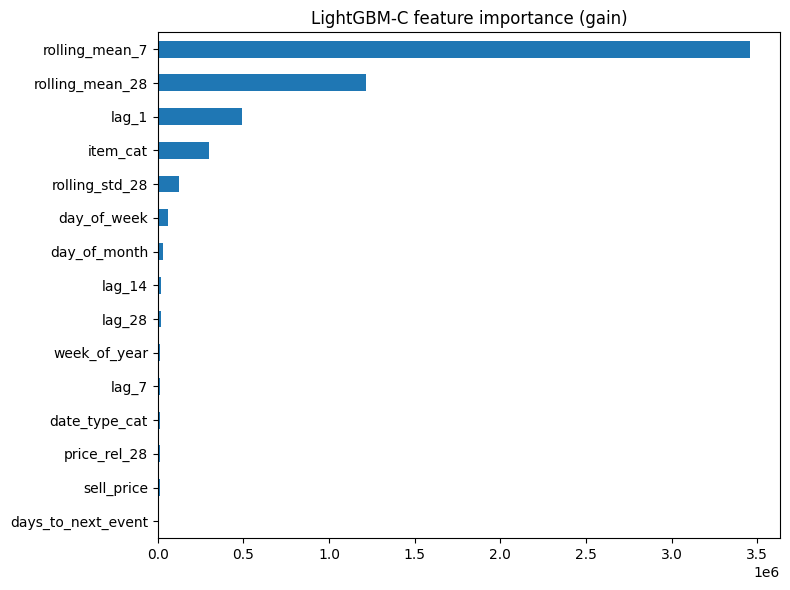

In [ ]:
import lightgbm as lgb

LGB_GRID = [dict(num_leaves=15, min_child_samples=50),
            dict(num_leaves=31, min_child_samples=20),
            dict(num_leaves=63, min_child_samples=20)]

lgb_models, lgb_best_params, lgb_val_log = {}, {}, []
for fs, cols in LGB_SETS.items():
    best = None
    for params in LGB_GRID:
        m = lgb.LGBMRegressor(objective="tweedie", tweedie_variance_power=1.2, n_estimators=3000,
                              learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                              random_state=SEED, verbose=-1, **params)
        m.fit(train[cols], train["demand"], eval_set=[(val[cols], val["demand"])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        v = wape(val["demand"].to_numpy(), np.clip(m.predict(val[cols]), 0, None))
        lgb_val_log.append({"set": fs, **params, "best_iter": m.best_iteration_, "val_WAPE_%": round(100 * v, 3)})
        if best is None or v < best[0]:
            best = (v, m, params)
    lgb_models[fs], lgb_best_params[fs] = best[1], best[2]
    test_eval[f"LightGBM-{fs}"] = np.clip(best[1].predict(test[cols]), 0, None)

print(pd.DataFrame(lgb_val_log).to_string(index=False))
print(metrics_table(test_eval, [f"LightGBM-{k}" for k in LGB_SETS]))

# feature importance (gain) for the full model C
imp = pd.Series(lgb_models["C"].booster_.feature_importance("gain"), index=LGB_SETS["C"]).sort_values()
imp.tail(15).plot(kind="barh", figsize=(8, 6), title="LightGBM-C feature importance (gain)")
save_fig("fig_lgb_importance.png")

## 11. LSTM (primary deep-learning model)
**Architecture (two-branch):**
* *History branch*: stacked LSTM encodes the last 28 days (log-demand [+ calendar, + price]).
* *Future branch*: the **known calendar / date type / SNAP / price of the forecast day** are concatenated with the LSTM state (this was missing in the old notebook, so the LSTM could not really be "calendar-aware").
* *Item embedding*: gives the LSTM the same item-identity information that LightGBM has.
* Output `softplus` + **Poisson loss** → non-negative expected demand, consistent with the Tweedie LightGBM. Inputs are standardised with statistics from the training period only.
* Sequences are built per item (no window crosses two items); a window belongs to train/val/test according to its **target date(s)**.

In [ ]:
# ---- standardise continuous inputs with TRAIN statistics only ----
SCALE_COLS = ["log_demand", "price_rel_28", "price_change_7"]
lstm_df = sales_long.copy()
tr_rows = lstm_df["split"] == "train"
mu, sd = lstm_df.loc[tr_rows, SCALE_COLS].mean(), lstm_df.loc[tr_rows, SCALE_COLS].std().replace(0, 1)
lstm_df[SCALE_COLS] = (lstm_df[SCALE_COLS] - mu) / sd

def build_sequences(df, hist_cols, fut_cols, lookback, horizon):
    """Vectorised, per-item sliding windows.
    Xh: (N, lookback, n_hist)  past window   | Xf: (N, horizon, n_fut) calendar etc. of the forecast days
    Y : (N, horizon) raw demand of the forecast days | start/end: first/last forecast date of each window"""
    out = {k: [] for k in ["Xh", "Xf", "item", "Y", "start", "end", "item_id"]}
    for item_id, g in df.groupby("item_id", sort=False):
        g = g.sort_values("date")
        n = len(g); m = n - lookback - horizon + 1
        if m <= 0:
            continue
        H_arr = g[hist_cols].to_numpy(np.float32)
        out["Xh"].append(sliding_window_view(H_arr, lookback, axis=0)[:m].transpose(0, 2, 1))
        y = g["demand"].to_numpy(np.float32)
        out["Y"].append(sliding_window_view(y, horizon)[lookback:lookback + m])
        if fut_cols:
            F_arr = g[fut_cols].to_numpy(np.float32)
            out["Xf"].append(sliding_window_view(F_arr, horizon, axis=0)[lookback:lookback + m].transpose(0, 2, 1))
        dts = g["date"].to_numpy()
        out["start"].append(dts[lookback:lookback + m])
        out["end"].append(dts[lookback + horizon - 1: lookback + horizon - 1 + m])
        out["item"].append(np.full(m, g["item_code"].iloc[0], dtype=np.int32))
        out["item_id"].append(np.full(m, item_id, dtype=object))
    seq = {k: (np.concatenate(v) if len(v) else None) for k, v in out.items()}
    seq["item"] = seq["item"].reshape(-1, 1)
    return seq

def split_masks(seq, t_end, v_end):
    t_end, v_end = np.datetime64(t_end), np.datetime64(v_end)
    tr = seq["end"] <= t_end                                     # whole target window inside train
    va = (seq["start"] > t_end) & (seq["end"] <= v_end)          # inside validation
    te = seq["start"] > v_end                                    # forecast origin in test
    return tr, va, te

def make_inputs(seq, mask):
    d = {"hist": seq["Xh"][mask], "item": seq["item"][mask]}
    if seq["Xf"] is not None:
        d["future"] = seq["Xf"][mask]
    return d

def attach_preds(base, seq, mask, pred_1d, col):
    tmp = pd.DataFrame({"item_id": seq["item_id"][mask],
                        "date": pd.to_datetime(seq["start"][mask]).astype("datetime64[ns]"),
                        col: np.asarray(pred_1d, dtype=float)})
    out = base.merge(tmp, on=["item_id", "date"], how="left")
    assert out[col].notna().all(), f"{col}: some test rows have no LSTM prediction"
    assert len(out) == len(base)
    return out

In [ ]:
import tensorflow as tf
from tensorflow.keras import layers, Model
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
print("TensorFlow", tf.__version__, "| GPU:", tf.config.list_physical_devices("GPU"))

def build_lstm(n_hist, n_fut, n_items, horizon=1, lookback=LOOKBACK):
    hist_in = layers.Input((lookback, n_hist), name="hist")
    item_in = layers.Input((1,), dtype="int32", name="item")
    emb = layers.Flatten()(layers.Embedding(n_items, 4)(item_in))
    h = layers.LSTM(LSTM_UNITS[0], return_sequences=True)(hist_in)
    h = layers.Dropout(DROPOUT)(h)
    h = layers.LSTM(LSTM_UNITS[1])(h)
    h = layers.Dropout(DROPOUT)(h)
    parts, inputs = [h, emb], [hist_in, item_in]
    if n_fut > 0:                                              # future-known covariates of the forecast day(s)
        fut_in = layers.Input((horizon, n_fut), name="future")
        parts.append(layers.Flatten()(fut_in)); inputs.append(fut_in)
    z = layers.Dense(32, activation="relu")(layers.Concatenate()(parts))
    out = layers.Dense(horizon, activation="softplus")(z)      # non-negative expected demand
    model = Model(inputs, out)
    model.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=LSTM_LOSS)
    return model

def make_callbacks():
    return [EarlyStopping(monitor="val_loss", patience=PATIENCE, restore_best_weights=True),
            ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=3, min_lr=1e-5)]

lstm_histories, lstm_run_log = {}, []
for fs, spec in LSTM_SETS.items():
    seq = build_sequences(lstm_df, spec["hist"], spec["fut"], LOOKBACK, HORIZON)
    tr, va, te = split_masks(seq, train_end, val_end)
    assert te.sum() == len(test_eval), f"Test windows ({te.sum()}) != test rows ({len(test_eval)})"
    print(f"\n=== LSTM-{fs}: train {tr.sum():,} | val {va.sum():,} | test {te.sum():,} windows ===")
    for seed in SEEDS:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        model = build_lstm(len(spec["hist"]), len(spec["fut"]), len(ITEM_LIST), HORIZON)
        t0 = time.time()
        hist = model.fit(make_inputs(seq, tr), seq["Y"][tr], validation_data=(make_inputs(seq, va), seq["Y"][va]),
                         epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=0)
        pred = np.clip(model.predict(make_inputs(seq, te), batch_size=2048, verbose=0)[:, 0], 0, None)
        test_eval = attach_preds(test_eval, seq, te, pred, f"LSTM-{fs}_s{seed}")
        lstm_histories[(fs, seed)] = hist.history
        lstm_run_log.append({"set": fs, "seed": seed, "epochs": len(hist.history["loss"]),
                             "best_val_loss": round(min(hist.history["val_loss"]), 5), "sec": round(time.time() - t0)})
        print(lstm_run_log[-1])
    test_eval[f"LSTM-{fs}"] = test_eval[[f"LSTM-{fs}_s{s}" for s in SEEDS]].mean(axis=1)   # seed ensemble
    del seq; gc.collect()

TensorFlow 2.20.0 | GPU: []

=== LSTM-A: train 99,319 | val 28,267 | test 28,700 windows ===
{'set': 'A', 'seed': 42, 'epochs': 40, 'best_val_loss': -1.94587, 'sec': 1577}
{'set': 'A', 'seed': 7, 'epochs': 32, 'best_val_loss': -1.94502, 'sec': 1241}
{'set': 'A', 'seed': 2024, 'epochs': 40, 'best_val_loss': -1.94719, 'sec': 1561}

=== LSTM-B: train 99,319 | val 28,267 | test 28,700 windows ===
{'set': 'B', 'seed': 42, 'epochs': 36, 'best_val_loss': -1.95752, 'sec': 1379}
{'set': 'B', 'seed': 7, 'epochs': 23, 'best_val_loss': -1.95691, 'sec': 882}
{'set': 'B', 'seed': 2024, 'epochs': 29, 'best_val_loss': -1.95523, 'sec': 1121}

=== LSTM-C: train 99,319 | val 28,267 | test 28,700 windows ===
{'set': 'C', 'seed': 42, 'epochs': 32, 'best_val_loss': -1.96251, 'sec': 1250}
{'set': 'C', 'seed': 7, 'epochs': 17, 'best_val_loss': -1.96064, 'sec': 661}
{'set': 'C', 'seed': 2024, 'epochs': 26, 'best_val_loss': -1.96162, 'sec': 1012}


## 12. Results (Report: Results and Discussion)
### 12.1 Main comparison – same test rows for every model

In [ ]:
MODEL_ORDER = ["Naive", "Seasonal Naive", "MA28"] + [f"LightGBM-{k}" for k in "ABC"] + [f"LSTM-{k}" for k in "ABC"]
MODEL_ORDER = [m for m in MODEL_ORDER if m in test_eval.columns]
results = metrics_table(test_eval, MODEL_ORDER)
print("Test set:", len(test_eval), "rows |", test_eval["date"].min().date(), "->", test_eval["date"].max().date())
display(results) if "display" in globals() else print(results)

# LSTM seed variability (single-seed metrics, mean ± std)
seed_cols = [c for c in test_eval.columns if c.startswith("LSTM-") and "_s" in c]
if seed_cols:
    rows = []
    for fs in "ABC":
        per_seed = pd.DataFrame({c: metrics_row(test_eval, c) for c in seed_cols if c.startswith(f"LSTM-{fs}_s")}).T
        if len(per_seed):
            rows.append({"set": f"LSTM-{fs}", "n_seeds": len(per_seed),
                         "WAPE_% mean": per_seed["WAPE_%"].mean(), "WAPE_% std": per_seed["WAPE_%"].std(),
                         "RMSE mean": per_seed["RMSE"].mean(), "RMSE std": per_seed["RMSE"].std()})
    print("\nLSTM across seeds:"); print(pd.DataFrame(rows).round(4).to_string(index=False))

Test set: 28700 rows | 2015-08-10 -> 2016-05-22
                   MAE    RMSE   WAPE_%   RMSSE    Bias  sMAPE_%(aux)
Naive           1.4456  2.9468  74.1171  1.0256 -0.0012       78.2650
Seasonal Naive  1.4838  2.8878  76.0750  1.0324  0.0038       82.8045
MA28            1.2658  2.4793  64.8984  0.7859 -0.0012      105.6971
LightGBM-A      1.2031  2.1667  61.6805  0.7613  0.0778      127.0693
LightGBM-B      1.1630  2.0905  59.6283  0.7498  0.0711      127.5557
LightGBM-C      1.1618  2.0909  59.5650  0.7492  0.0687      127.4745
LSTM-A          1.1924  2.1830  61.1335  0.7751  0.0887      128.2957
LSTM-B          1.1825  2.1746  60.6253  0.7695  0.0992      128.2804
LSTM-C          1.1834  2.1771  60.6701  0.7674  0.1122      127.9848

LSTM across seeds:
   set  n_seeds  WAPE_% mean  WAPE_% std  RMSE mean  RMSE std
LSTM-A        3      61.1768      0.2633     2.1866    0.0078
LSTM-B        3      60.7197      0.2616     2.1824    0.0153
LSTM-C        3      60.8136      0.3811     2

### 12.2 Ablation – does calendar / date-type information help? (RQ1)

In [ ]:
abl = []
for fam in ["LightGBM", "LSTM"]:
    if f"{fam}-A" not in results.index: continue
    base = results.loc[f"{fam}-A"]
    for fs in "ABC":
        r = results.loc[f"{fam}-{fs}"]
        abl.append({"model": fam, "feature set": fs,
                    "WAPE_%": r["WAPE_%"], "RMSE": r["RMSE"],
                    "WAPE change vs A (%)": 100 * (r["WAPE_%"] / base["WAPE_%"] - 1),
                    "RMSE change vs A (%)": 100 * (r["RMSE"] / base["RMSE"] - 1)})
abl = pd.DataFrame(abl).round(3)
print(abl.to_string(index=False))

# Diebold-Mariano tests (stat > 0 => first model is WORSE)
pairs = [("LightGBM-A", "LightGBM-B"), ("LightGBM-B", "LightGBM-C"), ("LSTM-A", "LSTM-B"), ("LSTM-B", "LSTM-C"),
         ("LightGBM-B", "LSTM-B"), ("LightGBM-C", "LSTM-C"), ("Seasonal Naive", "LightGBM-C"), ("Seasonal Naive", "LSTM-C")]
dm_rows = []
for a, b in pairs:
    if a in test_eval.columns and b in test_eval.columns:
        for loss in ["abs", "sq"]:
            s, p = dm_test(test_eval, a, b, loss)
            dm_rows.append({"model 1": a, "model 2": b, "loss": loss, "DM stat": round(s, 3), "p-value": round(p, 4),
                            "significant (5%)": p < 0.05, "better": b if s > 0 else a})
dm_df = pd.DataFrame(dm_rows)
print("\nDiebold-Mariano tests:"); print(dm_df.to_string(index=False))

   model feature set  WAPE_%  RMSE  WAPE change vs A (%)  RMSE change vs A (%)
LightGBM           A  61.680 2.167                 0.000                 0.000
LightGBM           B  59.628 2.090                -3.327                -3.517
LightGBM           C  59.565 2.091                -3.430                -3.498
    LSTM           A  61.134 2.183                 0.000                 0.000
    LSTM           B  60.625 2.175                -0.831                -0.385
    LSTM           C  60.670 2.177                -0.758                -0.270

Diebold-Mariano tests:
       model 1    model 2 loss  DM stat  p-value  significant (5%)     better
    LightGBM-A LightGBM-B  abs    6.896   0.0000              True LightGBM-B
    LightGBM-A LightGBM-B   sq    3.583   0.0003              True LightGBM-B
    LightGBM-B LightGBM-C  abs    1.206   0.2276             False LightGBM-C
    LightGBM-B LightGBM-C   sq   -0.112   0.9112             False LightGBM-B
        LSTM-A     LSTM-B  abs   

### 12.3 Error analysis by date type (RQ3) – the core of the "calendar-aware" claim

WAPE (%) by date type
             test_days  Seasonal Naive  LightGBM-A  LightGBM-C  LSTM-A  LSTM-C
date_type                                                                     
Weekday            160           80.00       65.76       62.67   65.27   63.44
Weekend             63           68.23       53.41       53.39   53.09   55.06
Pre_Event           41           76.25       61.61       60.26   59.90   60.46
Other_Event          7           77.29       60.20       57.96   59.50   59.62
Holiday             16           80.96       69.72       63.03   70.79   66.64

Bias by date type (>0 over-forecast, <0 under-forecast)
             Seasonal Naive  LightGBM-A  LightGBM-C  LSTM-A  LSTM-C
date_type                                                          
Weekday               0.037       0.244       0.091   0.212   0.109
Weekend              -0.041      -0.334       0.027  -0.225   0.104
Pre_Event            -0.051       0.022       0.084   0.025   0.133
Other_Event           0.036 

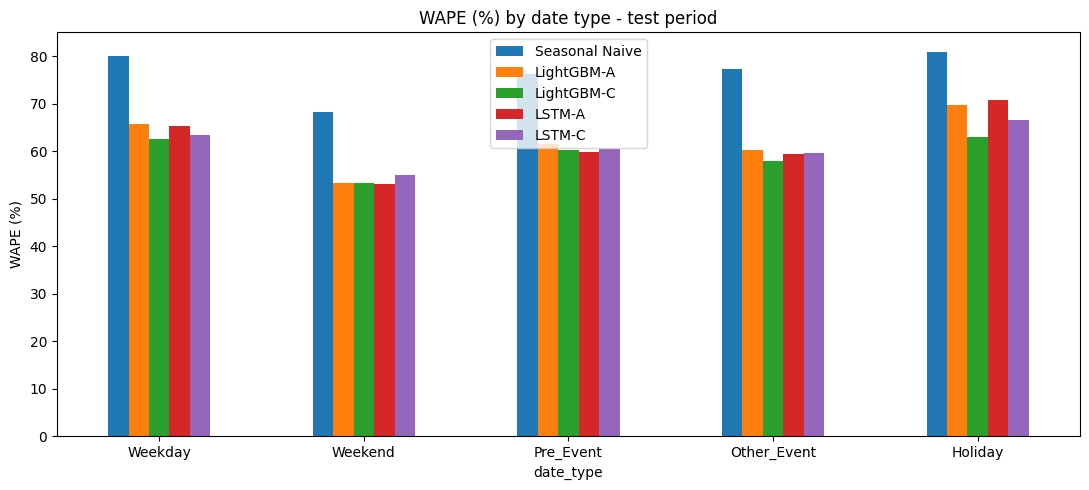

In [ ]:
cmp_models = [m for m in ["Seasonal Naive", "LightGBM-A", "LightGBM-C", "LSTM-A", "LSTM-C"] if m in test_eval.columns]

def grouped_metric(df, by, cols, fn):
    return pd.DataFrame({c: df.groupby(by).apply(lambda x: fn(x["demand"].to_numpy(float), x[c].to_numpy(float))) for c in cols})

wape_dt = (100 * grouped_metric(test_eval, "date_type", cmp_models, wape)).reindex(DATE_TYPES).round(2)
bias_dt = grouped_metric(test_eval, "date_type", cmp_models, bias).reindex(DATE_TYPES).round(3)
n_dt = test_eval.groupby("date_type")["date"].nunique().reindex(DATE_TYPES).rename("test_days")
print("WAPE (%) by date type"); print(pd.concat([n_dt, wape_dt], axis=1).to_string())
print("\nBias by date type (>0 over-forecast, <0 under-forecast)"); print(bias_dt.to_string())

wape_snap = (100 * grouped_metric(test_eval, "snap", cmp_models, wape)).round(2); wape_snap.index = ["non-SNAP", "SNAP"][:len(wape_snap)]
wape_vol = (100 * grouped_metric(test_eval, "vol_bin", cmp_models, wape)).round(2); wape_vol.index = [f"volume quintile {i+1}" for i in wape_vol.index]
print("\nWAPE (%) by SNAP day"); print(wape_snap.to_string())
print("\nWAPE (%) by item volume quintile (1 = slowest, 5 = fastest)"); print(wape_vol.to_string())

wape_dt.plot(kind="bar", figsize=(11, 5), rot=0, title="WAPE (%) by date type - test period"); plt.ylabel("WAPE (%)")
save_fig("fig_wape_by_date_type.png")

### 12.4 Forecast plots and training curves

Best model on test by WAPE: LightGBM-C


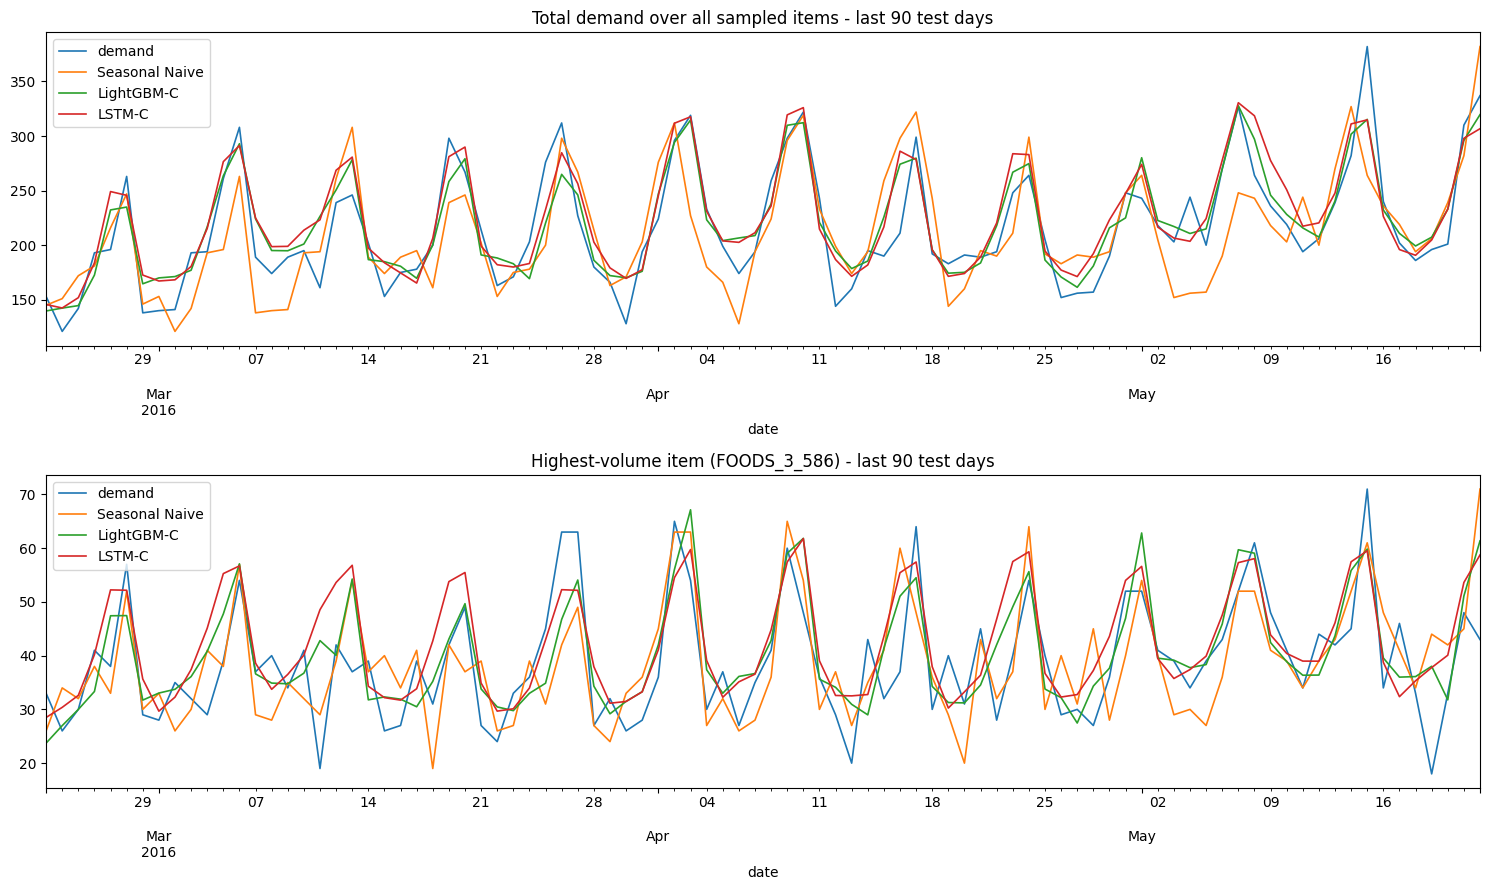

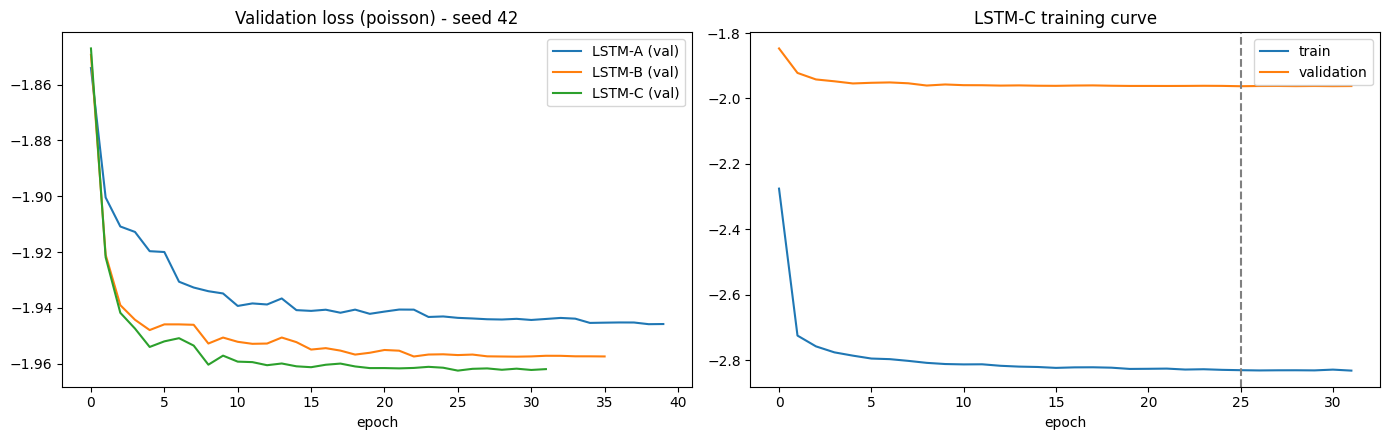

In [ ]:
best_name = results.loc[[m for m in results.index if m.startswith(("LightGBM", "LSTM"))], "WAPE_%"].idxmin()
print("Best model on test by WAPE:", best_name)

fig, ax = plt.subplots(2, 1, figsize=(15, 9))
agg_cols = ["demand"] + [m for m in ["Seasonal Naive", "LightGBM-C", "LSTM-C"] if m in test_eval.columns]
agg = test_eval.groupby("date")[agg_cols].sum()
agg.tail(90).plot(ax=ax[0], lw=1.2); ax[0].set_title("Total demand over all sampled items - last 90 test days")
top_item = test_eval.groupby("item_id")["demand"].sum().idxmax()
one = test_eval[test_eval["item_id"] == top_item].set_index("date")[agg_cols].tail(90)
one.plot(ax=ax[1], lw=1.2); ax[1].set_title(f"Highest-volume item ({top_item}) - last 90 test days")
save_fig("fig_actual_vs_pred.png")

if lstm_histories:
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
    for fs in "ABC":
        if (fs, SEEDS[0]) in lstm_histories:
            ax[0].plot(lstm_histories[(fs, SEEDS[0])]["val_loss"], label=f"LSTM-{fs} (val)")
    ax[0].set_title(f"Validation loss ({LSTM_LOSS}) - seed {SEEDS[0]}"); ax[0].set_xlabel("epoch"); ax[0].legend()
    h = lstm_histories[("C", SEEDS[0])]
    ax[1].plot(h["loss"], label="train"); ax[1].plot(h["val_loss"], label="validation")
    ax[1].axvline(int(np.argmin(h["val_loss"])), ls="--", color="gray")
    ax[1].set_title("LSTM-C training curve"); ax[1].set_xlabel("epoch"); ax[1].legend()
    save_fig("fig_lstm_curves.png")

## 13. Optional extension – 7-day-ahead forecasting (set `RUN_MULTISTEP = True` in the config)
Fair multi-step comparison requires **the same information at the forecast origin**:
* **LightGBM – direct strategy**: one model per horizon *h*; every history feature is taken at the origin day (*t − h*), calendar/price features are those of the target day *t*.
* **LSTM – direct multi-output**: one model predicts 7 days at once from the 28-day window plus the future calendar of those 7 days.
* Metrics are computed on the **intersection** of `(item_id, target_date, h)` rows, set C only.

In [ ]:
if RUN_MULTISTEP:
    H = MS_H
    cols_static = CAL_LGB + PRICE_LGB + ["item_cat"]

    # ---------- LightGBM direct, one model per horizon ----------
    ms = sales_long.copy()
    g_ms = ms.groupby("item_id", sort=False)["demand"]
    lgb_ms = []
    for h in range(1, H + 1):
        f = pd.DataFrame(index=ms.index)
        for name, sh in [("o_lag0", h), ("o_lag6", h + 6), ("o_lag13", h + 13), ("o_lag27", h + 27)]:
            f[name] = g_ms.shift(sh)
        f["o_same_dow"] = g_ms.shift(7)                       # same weekday last week (known for h <= 7)
        tmp = pd.DataFrame({"item_id": ms["item_id"], "_s": g_ms.shift(h)})
        f["o_roll7"]  = tmp.groupby("item_id", sort=False)["_s"].transform(lambda x: x.rolling(7).mean())
        f["o_roll28"] = tmp.groupby("item_id", sort=False)["_s"].transform(lambda x: x.rolling(28).mean())
        X = pd.concat([f, ms[cols_static]], axis=1)
        ok = X[["o_lag27", "o_roll28"]].notna().all(axis=1)
        tr_i, va_i, te_i = ok & (ms["split"] == "train"), ok & (ms["split"] == "val"), ok & (ms["split"] == "test")
        m = lgb.LGBMRegressor(objective="tweedie", tweedie_variance_power=1.2, n_estimators=3000, learning_rate=0.03,
                              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, random_state=SEED, verbose=-1,
                              **lgb_best_params["C"])
        m.fit(X[tr_i], ms.loc[tr_i, "demand"], eval_set=[(X[va_i], ms.loc[va_i, "demand"])],
              callbacks=[lgb.early_stopping(100, verbose=False)])
        lgb_ms.append(pd.DataFrame({"item_id": ms.loc[te_i, "item_id"].to_numpy(), "date": ms.loc[te_i, "date"].to_numpy(),
                                    "h": h, "demand": ms.loc[te_i, "demand"].to_numpy(),
                                    "LightGBM-C": np.clip(m.predict(X[te_i]), 0, None),
                                    "Seasonal Naive": X.loc[te_i, "o_same_dow"].to_numpy()}))
        print(f"LightGBM direct h={h} done")
    lgb_ms = pd.concat(lgb_ms, ignore_index=True)

    # ---------- LSTM multi-output ----------
    spec = LSTM_SETS["C"]
    seq = build_sequences(lstm_df, spec["hist"], spec["fut"], LOOKBACK, H)
    tr, va, te = split_masks(seq, train_end, val_end)
    lstm_ms_runs = []
    for seed in MS_SEEDS:
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
        model = build_lstm(len(spec["hist"]), len(spec["fut"]), len(ITEM_LIST), H)
        model.fit(make_inputs(seq, tr), seq["Y"][tr], validation_data=(make_inputs(seq, va), seq["Y"][va]),
                  epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=0)
        lstm_ms_runs.append(np.clip(model.predict(make_inputs(seq, te), batch_size=2048, verbose=0), 0, None))
    pred = np.mean(lstm_ms_runs, axis=0)                                   # (N_test_windows, H)
    start = pd.to_datetime(seq["start"][te]).astype("datetime64[ns]")
    lstm_ms = pd.concat([pd.DataFrame({"item_id": seq["item_id"][te], "date": start + pd.Timedelta(days=h),
                                       "h": h + 1, "LSTM-C": pred[:, h]}) for h in range(H)], ignore_index=True)

    ms_eval = lgb_ms.merge(lstm_ms, on=["item_id", "date", "h"], how="inner")   # identical rows for all models
    per_h = ms_eval.groupby("h").apply(lambda x: pd.Series({
        f"WAPE_% {c}": 100 * wape(x["demand"].to_numpy(float), x[c].to_numpy(float))
        for c in ["Seasonal Naive", "LightGBM-C", "LSTM-C"]})).round(2)
    print("Common evaluation rows:", len(ms_eval)); print(per_h)
    per_h.plot(marker="o", figsize=(9, 4.5), title="WAPE (%) by forecast horizon (set C)"); plt.xlabel("horizon h (days)")
    save_fig("fig_multistep_wape.png")
else:
    print("Multi-step extension skipped (RUN_MULTISTEP = False).")

Multi-step extension skipped (RUN_MULTISTEP = False).


## 14. Save outputs

In [ ]:
results.to_csv(os.path.join(OUT_DIR, "results_main.csv"))
abl.to_csv(os.path.join(OUT_DIR, "results_ablation.csv"), index=False)
dm_df.to_csv(os.path.join(OUT_DIR, "results_dm_tests.csv"), index=False)
wape_dt.to_csv(os.path.join(OUT_DIR, "results_wape_by_date_type.csv"))
test_eval.to_csv(os.path.join(OUT_DIR, "test_predictions.csv"), index=False)
print("Saved to", OUT_DIR)

Saved to /content/drive/MyDrive/HKI_2026/Học sâu và Ứng dụng trong Kinh doanh/Midterm/outputs


## 15. How to use these results in the report

**Results table (main):** copy `results` – report MAE, RMSE, WAPE, RMSSE, Bias; state that every model is evaluated on the same `(item, date)` rows and that LSTM numbers are the average of the seed ensemble (also give mean ± std over seeds).

**RQ1 – Do calendar features help?** Use the ablation table (A→B→C) for each model family and the DM tests. Be careful with wording: report the size of the change and its significance, not just the sign.

**RQ2 – LSTM vs LightGBM?** Compare LightGBM-X vs LSTM-X for the *same* feature set X. Many studies (e.g. the M5 competition) find tree-based models very strong on tabular retail data; do not assume DL must win – explain whichever result you obtain (data size, intermittent demand, the amount of exogenous information, tuning budget).

**RQ3 – Where do the errors come from?** Use the date-type, SNAP and volume-quintile tables and the bias table (over/under-forecasting around holidays has direct inventory consequences).

**Limitations to state honestly**
1. One store × one category and a sample of items – results may not generalise to other stores/categories.
2. Own chronological split (not the official M5 WRMSSE protocol) – numbers are not comparable with the Kaggle leaderboard.
3. Test period is ≈ 9 months, so it does not cover a full seasonal cycle (optional: repeat with a rolling-origin split).
4. LightGBM received a small hyper-parameter search; the LSTM architecture was fixed (units/dropout/learning-rate schedule only lightly set) – mention the unequal tuning budget.
5. Point forecasts only – no prediction intervals / service-level analysis.

## 16. Thí nghiệm bổ sung (phiên bản 3)

Đề tài được định vị lại: trọng tâm là **giá trị của thông tin lịch**, hai họ mô hình là công cụ đo. Các thí nghiệm dưới đây kiểm tra độ vững của kết luận, không thay đổi kết quả mục 12.

| Mục | Thí nghiệm | Câu hỏi |
|---|---|---|
| 16.1 | DM bổ sung (gồm LightGBM-A với LSTM-A) và trung bình LightGBM-C + LSTM-C | RQ2 |
| 16.2 | Bootstrap khối tuần cho chênh lệch WAPE, toàn bộ và theo loại ngày | RQ1, RQ3 |
| 16.3 | Đo thời gian huấn luyện và dự báo của LightGBM | RQ4 |
| 16.4 | LSTM được chọn từ 3 cấu hình như LightGBM (cùng ngân sách tinh chỉnh) | RQ2 |
| 16.5 | Permutation importance theo nhóm biến cho LightGBM-C và LSTM-C | RQ2 |
| 16.6 | Lưu kết quả | |

**Thời gian chạy.** 16.4 huấn luyện thêm tối đa 9 mô hình (3 cấu hình × 3 bộ, một seed) và 3 × 3 mô hình nếu cấu hình tốt nhất khác (64, 32). Trên CPU mỗi mô hình mất khoảng 11–26 phút, nên hãy chọn **Runtime → Change runtime type → T4 GPU**, hoặc đặt `RUN_LSTM_TUNING = False` để bỏ qua. Để so sánh chi phí công bằng (RQ4), đo thời gian của cả hai mô hình **trong cùng một phiên, cùng phần cứng**.

Hàm dùng trong mục này được chép nguyên văn từ `src/m5cal/supplementary.py` của repo (đã có kiểm thử trong `tests/test_supplementary.py`).

In [ ]:
# ===== 16.0 Cấu hình và hàm bổ sung (chép từ src/m5cal/supplementary.py) =====
RUN_LSTM_TUNING = True                 # False = bỏ qua 16.4
LSTM_GRID = [(32, 16), (64, 32), (128, 64)]  # 3 cấu hình, như lưới 3 cấu hình của LightGBM
TUNE_SETS = ["A", "B", "C"]
N_BOOT = 2000                          # số lần bootstrap
PI_REPEATS = 3                         # số lần hoán vị cho mỗi nhóm biến
SUPP = {}                              # nơi gom các bảng kết quả bổ sung

"""Thí nghiệm bổ sung cho thí nghiệm chính (notebook v3: CA_1 FOODS, 100 mặt hàng, dự báo 1 ngày tới).

Mọi hàm ở đây chỉ cần numpy/pandas/scipy và làm việc trên khung `test_eval` của notebook:
một dòng cho mỗi (item_id, date), cột `demand`, `date`, `date_type`, ... và một cột dự báo cho mỗi mô hình.
Notebook v3 chép nguyên văn tệp này vào một ô, nên mã trong notebook và mã được kiểm thử là một.

Nội dung
- wape, bias, dm_test_daily      : giống hệt định nghĩa trong notebook v2 (để số liệu khớp)
- dm_pairs_table                 : bảng Diebold–Mariano cho nhiều cặp mô hình
- block_bootstrap_wape_diff      : khoảng tin cậy cho chênh lệch WAPE, lấy mẫu lại theo khối tuần
- permutation_importance         : hoán vị theo nhóm biến, dùng chung cho LightGBM (DataFrame) và LSTM (mảng)
- permute_frame_columns, permute_array_channels : bộ hoán vị cho hai loại đầu vào
- Timer, add_ensemble            : đo thời gian chạy; trung bình dự báo nhiều mô hình
"""

import time
from typing import Callable, Mapping, Sequence

import numpy as np
import pandas as pd
from scipy import stats


# --------------------------------------------------------------------------- độ đo (giống notebook v2)
def wape(y, p) -> float:
    y = np.asarray(y, float)
    p = np.asarray(p, float)
    return float(np.abs(y - p).sum() / (np.abs(y).sum() + 1e-8))


def bias(y, p) -> float:
    return float(np.mean(np.asarray(p, float) - np.asarray(y, float)))


def dm_test_daily(df: pd.DataFrame, col1: str, col2: str, loss: str = "abs", lag: int = 7,
                  y_col: str = "demand", date_col: str = "date") -> tuple[float, float]:
    """Diebold–Mariano trên chênh lệch tổn thất cộng gộp theo ngày, phương sai Bartlett đến độ trễ `lag`.

    stat > 0 nghĩa là col1 có tổn thất CAO hơn (kém hơn) col2. Giống hàm dm_test của notebook v2.
    """
    e1 = df[y_col] - df[col1]
    e2 = df[y_col] - df[col2]
    if loss == "abs":
        l1, l2 = e1.abs(), e2.abs()
    elif loss == "sq":
        l1, l2 = e1 ** 2, e2 ** 2
    else:
        raise ValueError("loss phải là 'abs' hoặc 'sq'")
    d = (l1 - l2).groupby(df[date_col]).sum().to_numpy()
    n, dm = len(d), d.mean()
    var = np.var(d)
    for k in range(1, lag + 1):
        var += 2 * (1 - k / (lag + 1)) * np.mean((d[k:] - dm) * (d[:-k] - dm))
    if var <= 0:
        return float("nan"), float("nan")
    stat = dm / np.sqrt(var / n)
    return float(stat), float(2 * (1 - stats.norm.cdf(abs(stat))))


def dm_pairs_table(df: pd.DataFrame, pairs: Sequence[tuple[str, str]], losses=("abs", "sq"),
                   lag: int = 7, alpha: float = 0.05) -> pd.DataFrame:
    rows = []
    for a, b in pairs:
        if a not in df.columns or b not in df.columns:
            continue
        for loss in losses:
            s, p = dm_test_daily(df, a, b, loss, lag)
            rows.append({"model 1": a, "model 2": b, "loss": loss, "DM stat": round(s, 3),
                         "p-value": round(p, 4), f"significant ({int(alpha * 100)}%)": bool(p < alpha),
                         "better": b if s > 0 else a})
    return pd.DataFrame(rows)


# --------------------------------------------------------------------------- bootstrap theo khối tuần
def _week_key(dates: pd.Series) -> np.ndarray:
    d = pd.to_datetime(dates)
    return (d - pd.to_timedelta(d.dt.dayofweek, unit="D")).dt.normalize().to_numpy()


def block_bootstrap_wape_diff(df: pd.DataFrame, col_a: str, col_b: str, group_col: str | None = None,
                              n_boot: int = 2000, seed: int = 0, alpha: float = 0.05,
                              y_col: str = "demand", date_col: str = "date") -> pd.DataFrame:
    """Khoảng tin cậy cho WAPE(col_b) − WAPE(col_a), tính bằng điểm phần trăm.

    Lấy mẫu lại có hoàn lại các TUẦN lịch (khối 7 ngày) để giữ tương quan trong tuần; mọi dòng của tuần
    được chọn đi cùng nhau. Khi có `group_col` (ví dụ `date_type`), WAPE được tính riêng trong từng nhóm
    trên cùng một mẫu tuần. Giá trị âm nghĩa là col_b tốt hơn col_a.

    p_two_sided là tỷ lệ bootstrap hai phía quanh 0 (xấp xỉ, dùng để tham khảo cùng khoảng tin cậy).
    """
    rng = np.random.default_rng(seed)
    work = pd.DataFrame({
        "week": _week_key(df[date_col]),
        "g": df[group_col].to_numpy() if group_col else "Tất cả",
        "ae_a": (df[y_col] - df[col_a]).abs().to_numpy(float),
        "ae_b": (df[y_col] - df[col_b]).abs().to_numpy(float),
        "y": df[y_col].abs().to_numpy(float),
    })
    agg = work.groupby(["week", "g"], sort=True)[["ae_a", "ae_b", "y"]].sum()
    weeks = agg.index.get_level_values(0).unique()
    groups = list(pd.unique(work["g"]))
    # ma trận tuần × nhóm cho ba tổng
    cube = {k: agg[k].unstack("g").reindex(index=weeks, columns=groups).fillna(0.0).to_numpy() for k in ("ae_a", "ae_b", "y")}
    W = len(weeks)
    idx = rng.integers(0, W, size=(n_boot, W))
    out = []
    for j, g in enumerate(groups):
        A, B, Y = cube["ae_a"][:, j], cube["ae_b"][:, j], cube["y"][:, j]
        if Y.sum() <= 0:
            continue
        point = 100 * (B.sum() / Y.sum() - A.sum() / Y.sum())
        ys = Y[idx].sum(axis=1)
        ok = ys > 0
        diffs = 100 * (B[idx].sum(axis=1)[ok] - A[idx].sum(axis=1)[ok]) / ys[ok]
        lo, hi = np.quantile(diffs, [alpha / 2, 1 - alpha / 2])
        p = 2 * min((diffs <= 0).mean(), (diffs >= 0).mean())
        out.append({"group": g, "model a": col_a, "model b": col_b,
                    "WAPE a (%)": round(100 * A.sum() / Y.sum(), 2), "WAPE b (%)": round(100 * B.sum() / Y.sum(), 2),
                    "diff b-a (pp)": round(point, 2), "CI low": round(float(lo), 2), "CI high": round(float(hi), 2),
                    "p_two_sided": round(float(min(p, 1.0)), 4),
                    "CI excludes 0": bool(lo > 0 or hi < 0),
                    "weeks with data": int((Y > 0).sum()),
                    "days": int(df.loc[(df[group_col] == g) if group_col else slice(None), date_col].nunique())})
    return pd.DataFrame(out)


# --------------------------------------------------------------------------- permutation importance theo nhóm
Permuter = Callable[[object, np.random.Generator], object]


def permute_frame_columns(cols: Sequence[str]) -> Permuter:
    """Hoán vị CÙNG MỘT thứ tự dòng cho mọi cột trong nhóm (giữ quan hệ giữa các cột trong nhóm)."""
    cols = list(cols)

    def _perm(X: pd.DataFrame, rng: np.random.Generator) -> pd.DataFrame:
        Xp = X.copy()
        order = rng.permutation(len(X))
        for c in cols:
            vals = X[c].to_numpy()
            if isinstance(X[c].dtype, pd.CategoricalDtype):
                Xp[c] = pd.Categorical.from_codes(X[c].cat.codes.to_numpy()[order], dtype=X[c].dtype)
            else:
                Xp[c] = vals[order]
        return Xp

    return _perm


def permute_array_channels(spec: Mapping[str, Sequence[int] | None]) -> Permuter:
    """Hoán vị mẫu (trục 0) cho các kênh được chọn của nhiều mảng đầu vào, dùng chung một thứ tự.

    spec: {tên đầu vào: danh sách chỉ số kênh ở trục cuối, hoặc None = toàn bộ mảng}.
    Ví dụ nhóm lịch của LSTM-C: {"hist": [1, ..., 15], "future": [0, ..., 14]}.
    """
    spec = {k: (None if v is None else list(v)) for k, v in spec.items()}

    def _perm(inputs: Mapping[str, np.ndarray], rng: np.random.Generator) -> dict:
        n = len(next(iter(inputs.values())))
        order = rng.permutation(n)
        out = dict(inputs)
        for name, ch in spec.items():
            arr = np.array(inputs[name], copy=True)
            if ch is None:
                arr = arr[order]
            else:
                arr[..., ch] = arr[order][..., ch]
            out[name] = arr
        return out

    return _perm


def permutation_importance(predict_fn: Callable[[object], np.ndarray], inputs, y,
                           permuters: Mapping[str, Permuter], metric: Callable = wape,
                           n_repeats: int = 3, seed: int = 0) -> pd.DataFrame:
    """Mức tăng của `metric` (điểm phần trăm nếu metric là wape) khi hoán vị từng nhóm biến.

    predict_fn nhận đúng kiểu `inputs` (DataFrame cho LightGBM, dict mảng cho LSTM) và trả về dự báo.
    Dự báo được cắt tại 0 như trong notebook.
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y, float)
    base = metric(y, np.clip(np.asarray(predict_fn(inputs), float).ravel(), 0, None))
    rows = []
    for name, perm in permuters.items():
        scores = []
        for _ in range(n_repeats):
            pred = np.clip(np.asarray(predict_fn(perm(inputs, rng)), float).ravel(), 0, None)
            scores.append(metric(y, pred))
        scores = np.asarray(scores)
        rows.append({"group": name, "base": 100 * base, "permuted mean": 100 * scores.mean(),
                     "increase (pp)": 100 * (scores.mean() - base), "increase std (pp)": 100 * scores.std(ddof=0),
                     "repeats": n_repeats})
    return pd.DataFrame(rows).sort_values("increase (pp)", ascending=False).round(3).reset_index(drop=True)


# --------------------------------------------------------------------------- tiện ích
class Timer:
    """with Timer() as t: ...;  t.seconds"""

    def __enter__(self):
        self._t0 = time.perf_counter()
        self.seconds = float("nan")
        return self

    def __exit__(self, *exc):
        self.seconds = time.perf_counter() - self._t0
        return False


def add_ensemble(df: pd.DataFrame, cols: Sequence[str], name: str) -> pd.DataFrame:
    missing = [c for c in cols if c not in df.columns]
    if missing:
        raise KeyError(f"Thiếu cột dự báo: {missing}")
    df[name] = df[list(cols)].mean(axis=1)
    return df

### 16.1 Kiểm định Diebold–Mariano bổ sung và trung bình hai mô hình (RQ2)

In [ ]:
add_ensemble(test_eval, ["LightGBM-C", "LSTM-C"], "Ensemble-C")
SUPP["main_with_ensemble"] = metrics_table(test_eval, MODEL_ORDER + ["Ensemble-C"])
print(SUPP["main_with_ensemble"])

pairs_v3 = [("LightGBM-A", "LSTM-A"),                       # cặp còn thiếu ở mục 12.2
            ("LightGBM-A", "LightGBM-B"), ("LightGBM-B", "LightGBM-C"),
            ("LSTM-A", "LSTM-B"), ("LSTM-B", "LSTM-C"),
            ("LightGBM-B", "LSTM-B"), ("LightGBM-C", "LSTM-C"),
            ("LightGBM-C", "Ensemble-C"), ("LSTM-C", "Ensemble-C")]
SUPP["dm_v3"] = dm_pairs_table(test_eval, pairs_v3)
print("\nDiebold-Mariano (stat > 0 => model 1 kém hơn):")
print(SUPP["dm_v3"].to_string(index=False))

### 16.2 Bootstrap khối tuần cho chênh lệch WAPE (RQ1, RQ3)
Lấy mẫu lại có hoàn lại các tuần lịch của giai đoạn kiểm tra (giữ tương quan trong tuần). `diff b-a` < 0 nghĩa là mô hình b tốt hơn a. Với Holiday (7 ngày) và Other_Event (16 ngày), khoảng tin cậy sẽ rộng; hãy báo cáo đúng như vậy.

In [ ]:
boot_pairs = [("LightGBM-A", "LightGBM-B"), ("LightGBM-A", "LightGBM-C"),   # giá trị của lịch với LightGBM
              ("LSTM-A", "LSTM-B"), ("LSTM-A", "LSTM-C"),                   # giá trị của lịch với LSTM
              ("LSTM-A", "LightGBM-A"), ("LSTM-C", "LightGBM-C")]           # khoảng cách giữa hai họ
parts = []
for k, (a, b) in enumerate(boot_pairs):
    parts.append(block_bootstrap_wape_diff(test_eval, a, b, None, N_BOOT, SEED).assign(pair=k))
    parts.append(block_bootstrap_wape_diff(test_eval, a, b, "date_type", N_BOOT, SEED).assign(pair=k))
SUPP["bootstrap"] = pd.concat(parts, ignore_index=True)
order = ["Tất cả"] + DATE_TYPES
SUPP["bootstrap"]["group"] = pd.Categorical(SUPP["bootstrap"]["group"], categories=order, ordered=True)
SUPP["bootstrap"] = (SUPP["bootstrap"].sort_values(["pair", "group"]).drop(columns="pair")
                     .reset_index(drop=True))
print(SUPP["bootstrap"].to_string(index=False))

### 16.3 Chi phí tính toán của LightGBM (RQ4)
Huấn luyện lại LightGBM với cấu hình đã chọn ở mục 10 (cùng dừng sớm) và đo thời gian. Thời gian LSTM lấy từ `lstm_run_log` của mục 11 (gồm huấn luyện và dự báo cho mỗi seed) và từ 16.4 nếu chạy. Chỉ so sánh các con số đo trên cùng phần cứng.

In [ ]:
import platform
gpus = tf.config.list_physical_devices("GPU")
print("Phần cứng:", platform.processor() or platform.machine(), "| GPU:", gpus if gpus else "không có")

time_rows = []
for fs, cols in LGB_SETS.items():
    m_t = lgb.LGBMRegressor(objective="tweedie", tweedie_variance_power=1.2, n_estimators=3000,
                            learning_rate=0.03, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                            random_state=SEED, verbose=-1, **lgb_best_params[fs])
    with Timer() as t_fit:
        m_t.fit(train[cols], train["demand"], eval_set=[(val[cols], val["demand"])],
                callbacks=[lgb.early_stopping(100, verbose=False)])
    with Timer() as t_pred:
        m_t.predict(test[cols])
    time_rows.append({"model": f"LightGBM-{fs}", "fit_sec": round(t_fit.seconds, 1),
                      "predict_sec": round(t_pred.seconds, 2), "trees": m_t.best_iteration_})
SUPP["time_lgb"] = pd.DataFrame(time_rows)
print(SUPP["time_lgb"].to_string(index=False))

SUPP["time_lstm_v2"] = (pd.DataFrame(lstm_run_log).groupby("set")["sec"]
                        .agg(["mean", "min", "max", "count"]).rename(columns={"count": "seeds"}))
print("\nLSTM, mục 11 (giây mỗi seed, gồm huấn luyện + dự báo):")
print(SUPP["time_lstm_v2"])

### 16.4 Cùng ngân sách tinh chỉnh cho LSTM (RQ2)
LightGBM được chọn từ 3 cấu hình theo WAPE kiểm định; ở đây LSTM cũng được chọn từ 3 cấu hình (số đơn vị của hai lớp LSTM), một seed cho bước chọn, rồi huấn luyện lại cấu hình tốt nhất với cả 3 seed. Nếu cấu hình tốt nhất là (64, 32) như mục 11 thì dùng lại dự báo đã có. Kiến trúc còn lại giữ nguyên.

In [ ]:
def build_lstm_units(n_hist, n_fut, n_items, units, horizon=1, lookback=LOOKBACK):
    hist_in = layers.Input((lookback, n_hist), name="hist")
    item_in = layers.Input((1,), dtype="int32", name="item")
    emb = layers.Flatten()(layers.Embedding(n_items, 4)(item_in))
    h = layers.LSTM(units[0], return_sequences=True)(hist_in)
    h = layers.Dropout(DROPOUT)(h)
    h = layers.LSTM(units[1])(h)
    h = layers.Dropout(DROPOUT)(h)
    parts, inputs = [h, emb], [hist_in, item_in]
    if n_fut > 0:
        fut_in = layers.Input((horizon, n_fut), name="future")
        parts.append(layers.Flatten()(fut_in)); inputs.append(fut_in)
    z = layers.Dense(32, activation="relu")(layers.Concatenate()(parts))
    out = layers.Dense(horizon, activation="softplus")(z)
    mdl = Model(inputs, out)
    mdl.compile(optimizer=tf.keras.optimizers.Adam(1e-3), loss=LSTM_LOSS)
    return mdl

tune_rows, best_units, tuned_models, tuned_time = [], {}, {}, []
if RUN_LSTM_TUNING:
    for fs in TUNE_SETS:
        spec = LSTM_SETS[fs]
        seq = build_sequences(lstm_df, spec["hist"], spec["fut"], LOOKBACK, HORIZON)
        tr, va, te = split_masks(seq, train_end, val_end)
        y_val = seq["Y"][va][:, 0]
        cand = {}
        for units in LSTM_GRID:
            tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEEDS[0])
            mdl = build_lstm_units(len(spec["hist"]), len(spec["fut"]), len(ITEM_LIST), units, HORIZON)
            with Timer() as t:
                hh = mdl.fit(make_inputs(seq, tr), seq["Y"][tr], validation_data=(make_inputs(seq, va), seq["Y"][va]),
                             epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=0)
            pv = np.clip(mdl.predict(make_inputs(seq, va), batch_size=2048, verbose=0)[:, 0], 0, None)
            tune_rows.append({"set": fs, "units": str(units), "val_WAPE_%": round(100 * wape(y_val, pv), 3),
                              "epochs": len(hh.history["loss"]), "fit_sec": round(t.seconds)})
            cand[units] = (wape(y_val, pv), mdl)
            print(tune_rows[-1])
        best = min(cand, key=lambda u: cand[u][0])
        best_units[fs], tuned_models[fs] = best, cand[best][1]
        col = f"LSTM-{fs}-tuned"
        if tuple(best) == tuple(LSTM_UNITS):
            test_eval[col] = test_eval[f"LSTM-{fs}"]          # cùng cấu hình với mục 11: dùng lại
        else:
            for seed in SEEDS:
                tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(seed)
                mdl = build_lstm_units(len(spec["hist"]), len(spec["fut"]), len(ITEM_LIST), best, HORIZON)
                with Timer() as t:
                    mdl.fit(make_inputs(seq, tr), seq["Y"][tr], validation_data=(make_inputs(seq, va), seq["Y"][va]),
                            epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=0)
                    pred = np.clip(mdl.predict(make_inputs(seq, te), batch_size=2048, verbose=0)[:, 0], 0, None)
                tuned_time.append({"set": fs, "units": str(best), "seed": seed, "sec": round(t.seconds)})
                test_eval = attach_preds(test_eval, seq, te, pred, f"{col}_s{seed}")
                if seed == SEEDS[0]:
                    tuned_models[fs] = mdl
            test_eval[col] = test_eval[[f"{col}_s{s}" for s in SEEDS]].mean(axis=1)
        del seq; gc.collect()

    SUPP["lstm_tuning"] = pd.DataFrame(tune_rows)
    print("\nCấu hình LSTM được chọn:", best_units)
    tuned_cols = [f"LSTM-{fs}-tuned" for fs in TUNE_SETS]
    SUPP["main_tuned"] = metrics_table(test_eval, [f"LightGBM-{fs}" for fs in TUNE_SETS] + tuned_cols)
    print(SUPP["main_tuned"])
    SUPP["dm_tuned"] = dm_pairs_table(test_eval, [(f"LightGBM-{fs}", f"LSTM-{fs}-tuned") for fs in TUNE_SETS] +
                                      [("LSTM-A-tuned", "LSTM-B-tuned"), ("LSTM-B-tuned", "LSTM-C-tuned")])
    print(SUPP["dm_tuned"].to_string(index=False))
    if tuned_time:
        SUPP["time_lstm_tuned"] = pd.DataFrame(tuned_time)
else:
    print("Bỏ qua 16.4 (RUN_LSTM_TUNING = False).")

### 16.5 Permutation importance theo nhóm biến (RQ2)
Hoán vị từng nhóm thông tin trên tập kiểm tra và đo mức tăng WAPE (điểm phần trăm). Cùng một thước đo cho cả hai mô hình, khác với gain chỉ có cho LightGBM. Với LSTM, nhóm lịch được hoán vị đồng thời ở cửa sổ quá khứ và ở ngày dự báo. LSTM dùng mô hình một seed nên WAPE gốc khác chút ít so với dự báo trung bình ba seed.

In [ ]:
# --- LightGBM-C
X_c = test[LGB_SETS["C"]]
lgb_groups = {"Lịch sử nhu cầu": permute_frame_columns(HIST_LGB),
              "Lịch và loại ngày": permute_frame_columns(CAL_LGB),
              "Giá và SNAP": permute_frame_columns(PRICE_LGB),
              "Mã mặt hàng": permute_frame_columns(["item_cat"])}
pi_lgb = permutation_importance(lgb_models["C"].predict, X_c, test["demand"].to_numpy(), lgb_groups,
                                n_repeats=PI_REPEATS, seed=SEED).assign(model="LightGBM-C")

# --- LSTM-C: ưu tiên mô hình seed đầu của 16.4; nếu không có thì dùng mô hình LSTM-C cuối cùng của mục 11
spec = LSTM_SETS["C"]
seq = build_sequences(lstm_df, spec["hist"], spec["fut"], LOOKBACK, HORIZON)
tr, va, te = split_masks(seq, train_end, val_end)
lstm_pi_model = tuned_models.get("C")
if lstm_pi_model is None:
    ok = ("model" in globals() and len(model.inputs) == 3 and model.output_shape[-1] == 1
          and model.inputs[0].shape[-1] == len(spec["hist"]))
    if ok:
        lstm_pi_model = model                      # LSTM-C, seed cuối của mục 11
    else:                                          # ví dụ khi phần mở rộng 7 ngày đã ghi đè biến model
        tf.keras.backend.clear_session(); tf.keras.utils.set_random_seed(SEEDS[0])
        lstm_pi_model = build_lstm(len(spec["hist"]), len(spec["fut"]), len(ITEM_LIST), HORIZON)
        lstm_pi_model.fit(make_inputs(seq, tr), seq["Y"][tr], validation_data=(make_inputs(seq, va), seq["Y"][va]),
                          epochs=EPOCHS, batch_size=BATCH_SIZE, callbacks=make_callbacks(), verbose=0)

n_cal, n_pr = len(CAL_LSTM), len(PRICE_LSTM)
assert spec["hist"] == ["log_demand"] + CAL_LSTM + PRICE_LSTM and spec["fut"] == CAL_LSTM + PRICE_LSTM
cal_h, pr_h = list(range(1, 1 + n_cal)), list(range(1 + n_cal, 1 + n_cal + n_pr))
cal_f, pr_f = list(range(n_cal)), list(range(n_cal, n_cal + n_pr))
lstm_groups = {"Lịch sử nhu cầu": permute_array_channels({"hist": [0]}),
               "Lịch và loại ngày": permute_array_channels({"hist": cal_h, "future": cal_f}),
               "Giá và SNAP": permute_array_channels({"hist": pr_h, "future": pr_f}),
               "Mã mặt hàng": permute_array_channels({"item": None})}
lstm_predict = lambda inp: lstm_pi_model.predict(inp, batch_size=4096, verbose=0)[:, 0]
pi_lstm = permutation_importance(lstm_predict, make_inputs(seq, te), seq["Y"][te][:, 0], lstm_groups,
                                 n_repeats=PI_REPEATS, seed=SEED).assign(model="LSTM-C")
del seq; gc.collect()

SUPP["perm_importance"] = pd.concat([pi_lgb, pi_lstm], ignore_index=True)
print(SUPP["perm_importance"].to_string(index=False))
pivot = SUPP["perm_importance"].pivot(index="group", columns="model", values="increase (pp)")
pivot.plot(kind="barh", figsize=(9, 4.5), title="Mức tăng WAPE khi hoán vị nhóm biến (điểm %)")
plt.xlabel("tăng WAPE (điểm phần trăm)")
save_fig("fig_perm_importance_groups.png")

### 16.6 Lưu kết quả bổ sung
Thư mục `OUT_DIR` nằm trong bộ nhớ đệm của kagglehub và mất khi phiên Colab kết thúc. Đặt `SAVE_TO_DRIVE = True` để chép sang Google Drive.

In [ ]:
for name, tab in SUPP.items():
    tab.to_csv(os.path.join(OUT_DIR, f"supp_{name}.csv"), index=not isinstance(tab.index, pd.RangeIndex))
test_eval.to_csv(os.path.join(OUT_DIR, "test_predictions_v3.csv"), index=False)
print("Đã lưu:", sorted(f for f in os.listdir(OUT_DIR) if f.startswith("supp_")))

SAVE_TO_DRIVE = False
if SAVE_TO_DRIVE:
    import shutil
    from google.colab import drive
    drive.mount("/content/drive")
    dst = "/content/drive/MyDrive/M5_project/outputs_v3"
    shutil.copytree(OUT_DIR, dst, dirs_exist_ok=True)
    print("Đã chép sang", dst)

### 16.7 Đưa kết quả vào báo cáo
* **Mục 7.3 và 7.6 (RQ2):** dòng `LightGBM-A` / `LSTM-A` trong `dm_v3`; bảng `main_tuned` và `dm_tuned` (nếu LSTM vẫn kém ở bộ B, C sau khi tinh chỉnh, kết luận được củng cố; nếu khoảng cách thu hẹp, ghi nhận vai trò của tinh chỉnh); bảng `perm_importance` cho biết mỗi họ dựa vào nhóm thông tin nào.
* **Mục 7.2 và 7.4 (RQ1, RQ3):** bảng `bootstrap`; chỉ gọi là "có ý nghĩa" khi `CI excludes 0`.
* **RQ4:** `time_lgb` so với `time_lstm_v2` / `time_lstm_tuned`, ghi rõ phần cứng in ở 16.3.
* **Ensemble-C:** chỉ là phép thử phụ; báo cáo ngắn gọn trong phần thảo luận.